# Tutorial

Originally [from the Pyro intro](https://pyro.ai/examples/intro_long.html)

In [1]:
%reset -s -f


In [2]:
import logging
import os

import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import pyro

import pyro.distributions as dist
from pyro.nn import PyroModule, PyroSample
import torch.nn as nn

from pyro.infer import MCMC, NUTS
from pyro.infer import Predictive

# Construct data

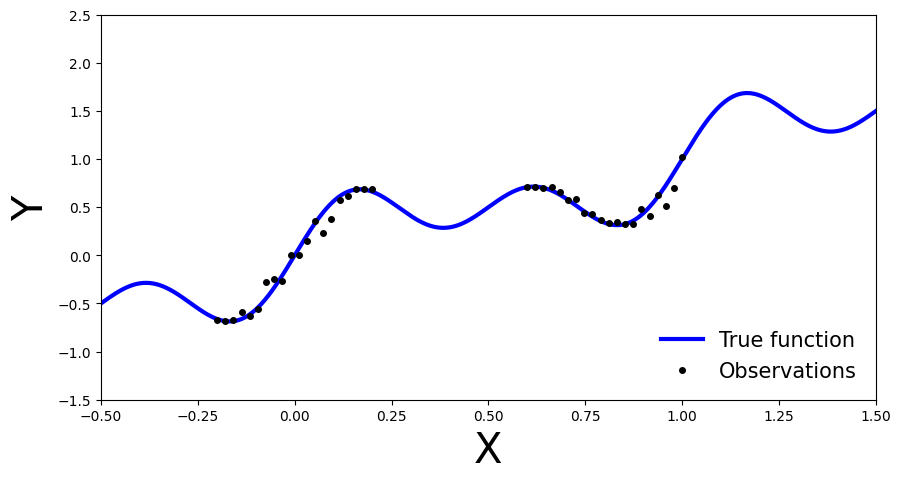

In [3]:


# Set random seed for reproducibility
np.random.seed(42)

nobs = 40

# Generate data
x_obs = np.hstack([np.linspace(-0.2, 0.2, nobs // 2), np.linspace(0.6, 1, nobs // 2)])
noise = 0.02 * np.random.randn(x_obs.shape[0])
y_obs = x_obs + 0.3 * np.sin(2 * np.pi * (x_obs + noise)) + 0.3 * np.sin(4 * np.pi * (x_obs + noise)) + noise

x_true = np.linspace(-0.5, 1.5, 1000)
y_true = x_true + 0.3 * np.sin(2 * np.pi * x_true) + 0.3 * np.sin(4 * np.pi * x_true)

# Convert data to PyTorch tensors
x_train = torch.from_numpy(x_obs).float()
y_train = torch.from_numpy(y_obs).float()

# Set plot limits and labels
xlims = [-0.5, 1.5]
ylims = [-1.5, 2.5]

x_test = torch.linspace(xlims[0], xlims[1], 3000)

# Create plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_true, y_true, 'b-', linewidth=3, label="True function")
ax.plot(x_obs, y_obs, 'ko', markersize=4, label="Observations")
ax.set_xlim(xlims)
ax.set_ylim(ylims)
ax.set_xlabel("X", fontsize=30)
ax.set_ylabel("Y", fontsize=30)
ax.legend(loc=4, fontsize=15, frameon=False)

plt.show()


# Tutorial Neural Network Test

[From UvA DL Notebooks](https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/DL2/Bayesian_Neural_Networks/dl2_bnn_tut1_students_with_answers.html)

In [ ]:



class MyFirstBNN(PyroModule):
    def __init__(self, in_dim=1, out_dim=1, hid_dim=5, prior_scale=10.):
        super().__init__()

        self.activation = nn.Tanh()  # or nn.ReLU()
        self.layer1 = PyroModule[nn.Linear](in_dim, hid_dim)  # Input to hidden layer
        self.layer2 = PyroModule[nn.Linear](hid_dim, out_dim)  # Hidden to output layer

        # Set layer parameters as random variables
        self.layer1.weight = PyroSample(dist.Normal(0., prior_scale).expand([hid_dim, in_dim]).to_event(2))
        self.layer1.bias = PyroSample(dist.Normal(0., prior_scale).expand([hid_dim]).to_event(1))
        self.layer2.weight = PyroSample(dist.Normal(0., prior_scale).expand([out_dim, hid_dim]).to_event(2))
        self.layer2.bias = PyroSample(dist.Normal(0., prior_scale).expand([out_dim]).to_event(1))

    def forward(self, x, y=None):
        x = x.reshape(-1, 1)
        x = self.activation(self.layer1(x))
        mu = self.layer2(x).squeeze()
        sigma = pyro.sample("sigma", dist.Gamma(.5, 1))  # Infer the response noise

        # Sampling model
        with pyro.plate("data", x.shape[0]):
            obs = pyro.sample("obs", dist.Normal(mu, sigma * sigma), obs=y)
        return mu

In [ ]:


model = MyFirstBNN()



In [ ]:
# Set Pyro random seed
pyro.set_rng_seed(42)

# Define Hamiltonian Monte Carlo (HMC) kernel
# NUTS = "No-U-Turn Sampler" (https://arxiv.org/abs/1111.4246), gives HMC an adaptive step size
nuts_kernel = NUTS(model, jit_compile=True)  # jit_compile=True is faster but requires PyTorch 1.6+

# Define MCMC sampler, get 50 posterior samples
mcmc = MCMC(nuts_kernel, num_samples=50)

# Run MCMC
mcmc.run(x_train, y_train)

In [ ]:


predictive = Predictive(model=model, posterior_samples=mcmc.get_samples())
preds = predictive(x_test)

In [ ]:
def plot_predictions(preds):
    y_pred = preds['obs'].T.detach().numpy().mean(axis=1)
    y_std = preds['obs'].T.detach().numpy().std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [-0.5, 1.5]
    ylims = [-1.5, 2.5]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)

    ax.plot(x_true, y_true, 'b-', linewidth=3, label="true function")
    ax.plot(x_obs, y_obs, 'ko', markersize=4, label="observations")
    ax.plot(x_obs, y_obs, 'ko', markersize=3)
    ax.plot(x_test, y_pred, '-', linewidth=3, color="#408765", label="predictive mean")
    ax.fill_between(x_test, y_pred - 2 * y_std, y_pred + 2 * y_std, alpha=0.6, color='#86cfac', zorder=5)

    plt.legend(loc=4, fontsize=15, frameon=False)

In [ ]:
plot_predictions(preds)

In [ ]:
class BNN(PyroModule):
    def __init__(self, in_dim=1, out_dim=1, hid_dim=10, n_hid_layers=5, prior_scale=5.):
        super().__init__()

        self.activation = nn.Tanh()  # could also be ReLU or LeakyReLU
        assert in_dim > 0 and out_dim > 0 and hid_dim > 0 and n_hid_layers > 0  # make sure the dimensions are valid

        # Define the layer sizes and the PyroModule layer list
        self.layer_sizes = [in_dim] + n_hid_layers * [hid_dim] + [out_dim]
        layer_list = [PyroModule[nn.Linear](self.layer_sizes[idx - 1], self.layer_sizes[idx]) for idx in
                      range(1, len(self.layer_sizes))]
        self.layers = PyroModule[torch.nn.ModuleList](layer_list)

        for layer_idx, layer in enumerate(self.layers):
            layer.weight = PyroSample(dist.Normal(0., prior_scale * np.sqrt(2 / self.layer_sizes[layer_idx])).expand(
                [self.layer_sizes[layer_idx + 1], self.layer_sizes[layer_idx]]).to_event(2))
            layer.bias = PyroSample(dist.Normal(0., prior_scale).expand([self.layer_sizes[layer_idx + 1]]).to_event(1))

    def forward(self, x, y=None):
        x = x.reshape(-1, 1)
        x = self.activation(self.layers[0](x))  # input --> hidden
        for layer in self.layers[1:-1]:
            x = self.activation(layer(x))  # hidden --> hidden
        mu = self.layers[-1](x).squeeze()  # hidden --> output
        sigma = pyro.sample("sigma", dist.Gamma(.5, 1))  # infer the response noise

        with pyro.plate("data", x.shape[0]):
            obs = pyro.sample("obs", dist.Normal(mu, sigma * sigma), obs=y)
        return mu

In [ ]:
# define model and data
model = BNN(hid_dim=10, n_hid_layers=5, prior_scale=5.)

# define MCMC sampler
nuts_kernel = NUTS(model, jit_compile=True)
mcmc = MCMC(nuts_kernel, num_samples=50,    warmup_steps=50)
mcmc.run(x_train, y_train)

In [ ]:
predictive = Predictive(model=model, posterior_samples=mcmc.get_samples())
preds = predictive(x_test)
plot_predictions(preds)

In [ ]:
print(mcmc.get_samples().keys())
mcmc.get_samples()["layers.0.weight"].shape

# Using a replicated infinite BNN class

### Build model and examine prior

In [4]:
from mmbo.nn import TIBNN

In [5]:
x_train2 = x_train.reshape((*x_train.shape, 1))
y_train2 = y_train.reshape((*y_train.shape, 1))
x_test2 = x_test.reshape((*x_test.shape, 1))

In [47]:
# define model and data
bias_ordering = True

model = TIBNN.from_data(x_train2, y_train2, width=200, depth=2, bias_ordering=bias_ordering)


In [36]:
x_test2.shape[:-1]

torch.Size([3000])

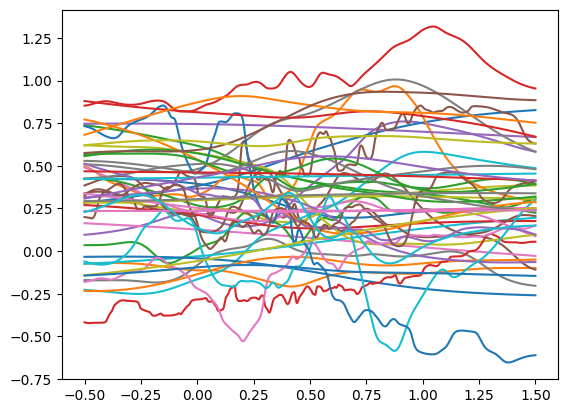

In [48]:
num_plot = 50
#width = 100
#depth = 3

pltpoints = 1000

###########################

fig, axs = plt.subplots()


x = x_test2

#model = TIBNN(n_feat=1, n_out=1, width=width, depth=depth)

for _ in range(num_plot):
    y = model(x)
    axs.plot(x.flatten(), y.flatten())




### Sample from model using MCMC

In [39]:
# Sample from Posterior using MCMC

# define MCMC sampler
nuts_kernel = NUTS(model, jit_compile=True, full_mass=False)
mcmc = MCMC(nuts_kernel, num_samples=20,    warmup_steps=50)
mcmc.run(x_train2, y_train2)

Warmup:   0%|          | 0/70 [00:00, ?it/s]c:\Users\itaylor\Documents\Fastmath\mmbo\.venv\Lib\site-packages\pyro\distributions\torch_patch.py:74: TracerWarning: torch.as_tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  value = torch.as_tensor(
c:\Users\itaylor\Documents\Fastmath\mmbo\.venv\Lib\site-packages\pyro\poutine\subsample_messenger.py:70: TracerWarning: torch.tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  result = torch.tensor(0.0, device=self.device)
c:\Users\itaylor\Documents\Fastmath\mmbo\.venv\Lib\site-package

In [40]:
print({k:mcmc.get_samples()[k].shape for k in mcmc.get_samples().keys()})
print(mcmc.get_samples()['sigma'].mean())

{'_chain.0.bias': torch.Size([20, 200]), '_chain.0.weight': torch.Size([20, 200, 1]), '_chain.1.scale': torch.Size([20]), '_chain.2.bias': torch.Size([20, 200]), '_chain.2.weight': torch.Size([20, 200, 200]), '_chain.3.scale': torch.Size([20]), '_chain.4.weight': torch.Size([20, 1, 200]), 'sigma': torch.Size([20])}
tensor(0.0753)


In [41]:
predictive = Predictive(model=model, posterior_samples=mcmc.get_samples(), return_sites=["obs","mu","_chain.0.bias"])
preds = predictive(x_test2)
print({k:preds[k].shape for k in preds})

{'_chain.0.bias': torch.Size([20, 1, 200]), 'obs': torch.Size([20, 3000, 1]), 'mu': torch.Size([20, 3000, 1])}


In [42]:
def plot_predictions2(preds):
    y_pred = preds['mu'].squeeze().T.detach().numpy().mean(axis=1)
    y_std = preds['mu'].squeeze().T.detach().numpy().std(axis=1)

    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [-0.5, 1.5]
    ylims = [-1.5, 2.5]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)

    ax.plot(x_true, y_true, 'b-', linewidth=3, label="true function")
    ax.plot(x_obs, y_obs, 'ko', markersize=4, label="observations")
    ax.plot(x_obs, y_obs, 'ko', markersize=3)
    ax.plot(x_test, y_pred, '-', linewidth=3, color="#408765", label="predictive mean")
    ax.fill_between(x_test, y_pred - 2 * y_std, y_pred + 2 * y_std, alpha=0.6, color='#86cfac', zorder=5)

    plt.legend(loc=4, fontsize=15, frameon=False)

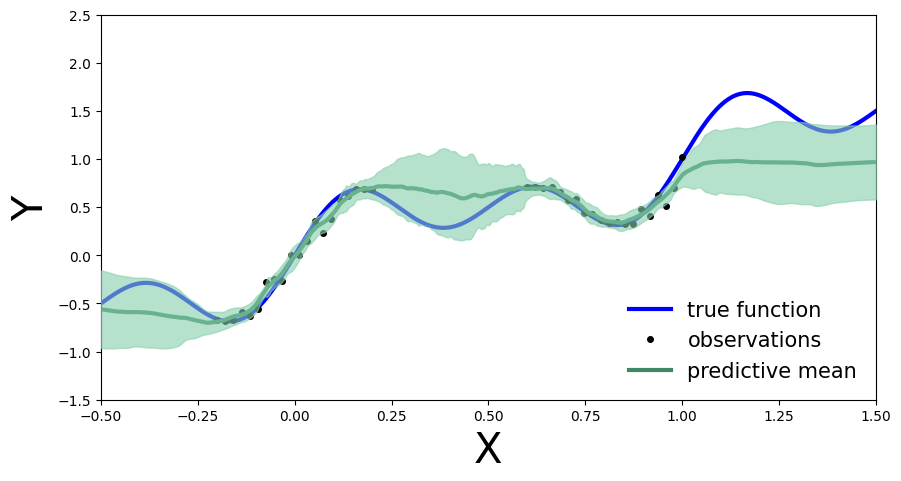

In [43]:
plot_predictions2(preds)

### Fit posterior using SVI

Elbo loss: 2650751.9087994583
Elbo loss: 209964.26318362355
Elbo loss: 68563.91431839019
Elbo loss: 31402.755868315697
Elbo loss: 16137.553069025278
Elbo loss: 9293.011401176453
Elbo loss: 5860.165655732155
Elbo loss: 4572.358529210091
Elbo loss: 3712.7617790699005
Elbo loss: 3285.4459958672523


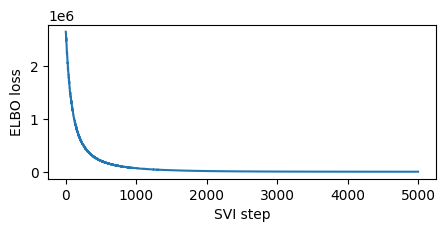

In [68]:
# Fit posterior using SVI
logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

auto_guide = pyro.infer.autoguide.AutoNormal(model)
adam = pyro.optim.Adam({"lr": 0.005})
elbo = pyro.infer.Trace_ELBO()
svi = pyro.infer.SVI(model, auto_guide, adam, elbo)

losses = []
for step in range(5000):  # Consider running for more steps.
    loss = svi.step(x_train2, y_train2)
    losses.append(loss)
    if step % 500 == 0:
        logging.info("Elbo loss: {}".format(loss))

plt.figure(figsize=(5, 2))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

In [65]:
svi_predictive = Predictive(model, guide=auto_guide, num_samples=50)
svi_samples = svi_predictive(x_test2)
print({k:svi_samples[k].shape for k in svi_samples})

{'sigma': torch.Size([50, 1]), '_chain.0.weight': torch.Size([50, 1, 200, 1]), '_chain.0.bias': torch.Size([50, 1, 200]), '_chain.1.scale': torch.Size([50, 1]), '_chain.2.weight': torch.Size([50, 1, 200, 200]), '_chain.2.bias': torch.Size([50, 1, 200]), '_chain.3.scale': torch.Size([50, 1]), '_chain.4.weight': torch.Size([50, 1, 1, 200]), 'obs': torch.Size([50, 3000, 1]), 'mu': torch.Size([50, 3000, 1])}


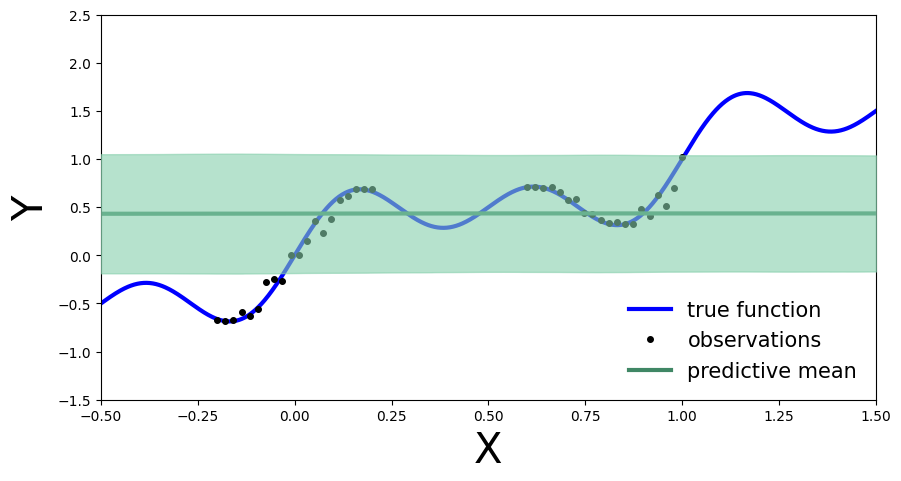

In [66]:
plot_predictions2(svi_samples)

In [70]:
svi_samples['sigma'].mean(dim=0).mean(dim=0)

tensor(0.5959)

In [59]:
pyro.get_param_store().keys()

dict_keys(['AutoLowRankMultivariateNormal.loc', 'AutoLowRankMultivariateNormal.scale', 'AutoLowRankMultivariateNormal.cov_factor'])

### Fit model using NeuTra reparameterized HMC

In [ ]:
neutra = pyro.infer.reparam.NeuTraReparam(auto_guide)
model = poutine.reparam(model, config=lambda _: neutra)
nuts = NUTS(model)